# 개념 정리

### 5.2. 합성곱 신경망 맛보기

GPU 사용
- 하나의 GPU를 사용할 때는 torch.device("cuda:0" if~)로 설정하여 model = Net(); model.to(device)로 설정
- 다수의 GPU를 사용할 때는 nn.DataParallel을 이용해 model = nn.DataParallel(net)으로 설정
- nn.DataParallel을 사용할 경우 배치 크기가 알아서 각 GPU로 분배되는 방식. GPU 수만큼 배치 크기도 늘려주어야 함.

torchvision.datasets.FashionMNIST(path, download, transform)
- 첫번째 path: 내려받을 위치
- download=True: 위치에 해당 데이터셋이 있는지 확인한 후 내려받음
- transform=transforms.Compose([transforms.ToTensor()]): 이미지를 텐서(0~1)로 변경

torch.utils.data.DataLoader(train_dataset, batch_size)
- 첫번째 train_dataset: 데이터를 불러올 데이터셋 지정
- batch_size=100: 데이터를 배치로 묶어줌. 100개 단위로 묶어서 불러옴.

np.random
- np.random.randint(10): 0~10의 임의의 숫자 출력
- np.random.randint(1, 10): 1~9의 임의의 숫자를 출력
- np.random.rand(8): 0~1 사이의 정규분포 난수를 행렬(1x8)로 출력
- np.random.rand(4, 2): 0~1 사이의 정규분포 난수를 행렬(4, 2)로 출력
- np.random.randn(8): 가우시안 정규분포 난수를 행렬(1x8)로 출력
- np.random.randn(4, 2): 가우시안 정규분포 난수를 행렬(4x2)로 출력

클래스 형태의 모델: torch.nn.Module 상속. __init__()으로 객체가 갖는 속성 값 초기화, 객체 생성 시 자동 호출. super(model, self).__init__()은 nn.Module 클래스를 상속받는다는 의미.

- torch.nn.Dropout(p): p만큼의 비율로 텐서의 값이 0이 되고, 0이 되지 않는 값들은 기존 값에 (1/(1-p))만큼 곱해져 커짐.  
- forward() 함수: 모델이 학습 데이터를 입력받아 순전파(forward propagation) 학습 진행. H(x)식에 입력 x로부터 예측된 y를 얻음.
- 파이토치의 view: 넘파이의 reshape과 같은 역할로 텐서의 크기를 변경

활성화 함수 지정
- nn.xx: 클래스 형태. nn.Module 클래스를 상속받아 사용. 먼저 하이퍼파라미터를 전달한 후 함수 호출을 통해 데이터 전달. nn.Sequential 내에 위치. 파라미터를 새로 정의할 필요 없음.
- nn.functional.xx: 함수 형태. 함수를 호출할 때 하이퍼파라미터, 데이터 전달. nn.Sequential에 위치할 수 없음. 가중치를 수동으로 전달해야 할 때마다 자체 가중치를 정의.

Autograd: 자동 미분을 수행하는 패키지. 자동 미분에 대한 값을 저장하기 위해 테이프(tape) 사용. 순전파 단계에서 수행하는 모든 연산을 저장한 후 역전파 단계에서 꺼내 사용함. Variable을 사용해 역전파를 위한 미분값을 자동으로 계산해 줌.

nn.Sequential: 계층을 차례로 쌓을 수 있도록 수식과 활성화 함수를 연결해주는 역할. 데이터가 각 계층을 순차적으로 지나갈 때 사용.

nn.Conv2d(in_channels, out_channels, kernel_size, padding)
- in_channels: 입력 채널의 수
- out_channels: 출력 채널의 수
- kernel_size: 커널 크기. 필터라고도 함. 커널은 이미지 특징을 찾아내기 위한 공용 파라미터로 입력 데이터를 스트라이드 간격으로 순회하면서 합성곱을 계산함.
- padding: 패딩 크기. 출력 크기를 조정하기 위해 입력 데이터 주위에 0을 채움.

- BatchNorm2d: 학습 과정에서 각 배치 단위별로 데이터를 정규화
- MaxPool2d: 이미지 크기를 축소시키는 용도. 풀링 계층은 합성곱층의 출력 데이터를 입력으로 받아 출력 데이터의 크기를 죽이거나 특정 데이터를 강조하는 용도로 사용됨. 풀링 계층 처리 방법에는 최대 풀링, 평균 풀링, 최소 풀링이 있음.

# 코드 필사

### 5.2. 합성곱 신경망 맛보기

In [1]:
# 라이브러리 호출

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.autograd import Variable
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms # 데이터 전처리를 위해 사용하는 라이브러리
from torch.utils.data import Dataset, DataLoader

In [ ]:
# CPU 혹은 GPU 장치 확인

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [3]:
# fashion_mnist 데이터셋 내려받기

train_dataset = torchvision.datasets.FashionMNIST("./data", download=True,
                                                  transform=transforms.Compose([transforms.ToTensor()]))
test_dataset = torchvision.datasets.FashionMNIST("./data", download=True, train=False,
                                                 transform=transforms.Compose([transforms.ToTensor()]))

100%|██████████| 26.4M/26.4M [00:06<00:00, 4.10MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 107kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


In [4]:
# fashion_mnist 데이터를 데이터로더에 전달

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=100)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=100)

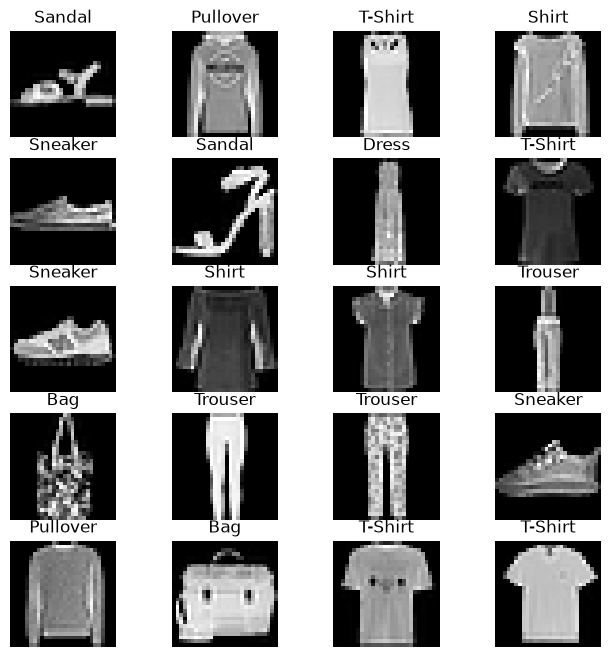

In [5]:
# 분류에 사용될 클래스 정의

labels_map = {0 : 'T-Shirt', 1 : 'Trouser', 2 : 'Pullover', 3 : 'Dress', 4 : 'Coat', 5 : 'Sandal',
              6: 'Shirt', 7 : 'Sneaker', 8 : 'Bag', 9 : 'Ankle Boot'} # 열 개의 클래스

fig = plt.figure(figsize=(8, 8)) # 출력할 이미지의 가로세로 길이로 단위는 inch
columns = 4
rows = 5
for i in range(1, columns*rows + 1):
    img_xy = np.random.randint(len(train_dataset))
    img = train_dataset[img_xy][0][0, :, :]
    fig.add_subplot(rows, columns, i)
    plt.title(labels_map[train_dataset[img_xy][1]])
    plt.axis('off')
    plt.imshow(img, cmap='gray')
plt.show()

In [11]:
# 심층 신경망 모델 생성

class FashionDNN(nn.Module):
    def __init__(self):
        super(FashionDNN, self).__init__()
        self.fc1 = nn.Linear(in_features=784, out_features=256)
        self.drop = nn.Dropout(0.25)
        self.fc2 = nn.Linear(in_features=256, out_features=128)
        self.fc3 = nn.Linear(in_features=128, out_features=10)

    def forward(self, input_data):
        out = input_data.view(-1, 784)
        out = F.relu(self.fc1(out))
        out = self.drop(out)
        out = F.relu(self.fc2(out))
        out = self.fc3(out)
        return out

In [12]:
# 심층 신경망에서 필요한 파라미터 정의

learning_rate = 0.001
model = FashionDNN()
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
print(model)

FashionDNN(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)


In [14]:
# 심층 신경망을 이용한 모델 학습

num_epochs = 5
count = 0
loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        train = Variable(images.view(100, 1, 28, 28))
        labels = Variable(labels)

        outputs = model(train)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        count += 1

        if not (count % 50) : # count를 50으로 나누었을 때 나머지가 0이 아니라면 실행
            total = 0
            correct = 0
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                labels_list.append(labels)
                test = Variable(images.view(100, 1, 28, 28))
                outputs = model(test)
                predictions = torch.max(outputs, 1)[1].to(device)
                predictions_list.append(predictions)
                correct += (predictions == labels).sum()
                total += len(labels)

            accuracy = correct * 100 / total
            loss_list.append(loss.data)
            iteration_list.append(count)
            accuracy_list.append(accuracy)

        if not (count % 500):
            print("Iteration: {}, Loss: {}, Accuracy: {}%".format(count, loss.data, accuracy))

Iteration: 500, Loss: 0.6069558262825012, Accuracy: 83.70999908447266%
Iteration: 1000, Loss: 0.49999329447746277, Accuracy: 84.45999908447266%
Iteration: 1500, Loss: 0.3933335244655609, Accuracy: 84.33999633789062%
Iteration: 2000, Loss: 0.32315829396247864, Accuracy: 85.3699951171875%
Iteration: 2500, Loss: 0.2530590891838074, Accuracy: 85.86000061035156%
Iteration: 3000, Loss: 0.2807174026966095, Accuracy: 86.48999786376953%


In [15]:
# 합성곱 네트워크 생성

class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.layer2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc1 = nn.Linear(in_features=64*6*6, out_features=600)
        self.drop = nn.Dropout2d(0.25)
        self.fc2 = nn.Linear(in_features=600, out_features=120)
        self.fc3 = nn.Linear(in_features=120, out_features=10) # 마지막 계층의 out_features는 클래스 개수를 의미

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        out = self.drop(out)
        out = self.fc2(out)
        out = self.fc3(out)
        return out

In [16]:
# 합성곱 네트워크를 위한 파라미터 정의

learning_rate = 0.001
model = FashionCNN()
model.to(device)

criterion = nn.CrossEntropyLoss();
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
print(model)

FashionCNN(
  (layer1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=2304, out_features=600, bias=True)
  (drop): Dropout2d(p=0.25, inplace=False)
  (fc2): Linear(in_features=600, out_features=120, bias=True)
  (fc3): Linear(in_features=120, out_features=10, bias=True)
)


In [17]:
# 모델 학습 및 성능 평가

num_epochs = 5
count = 0
loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        train = Variable(images.view(100, 1, 28, 28))
        labels = Variable(labels)

        outputs = model(train)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        count += 1

        if not (count % 50):
            total = 0
            correct = 0
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                labels_list.append(labels)
                test = Variable(images.view(100, 1, 28, 28))
                outputs = model(test)
                predictions = torch.max(outputs, 1)[1].to(device)
                predictions_list.append(predictions)
                correct += (predictions == labels).sum()
                total += len(labels)

            accuracy = correct * 100 / total
            loss_list.append(loss.data)
            iteration_list.append(count)
            accuracy_list.append(accuracy)

        if not (count % 500):
            print("Iteration: {}, Loss: {}, Accuracy: {}%".format(count, loss.data, accuracy))

f:\ESAA\.venv\Lib\site-packages\torch\nn\modules\dropout.py:176: UserWarning: dropout2d: Received a 2-D input to dropout2d, which is deprecated and will result in an error in a future release. To retain the behavior and silence this warning, please use dropout instead. Note that dropout2d exists to provide channel-wise dropout on inputs with 2 spatial dimensions, a channel dimension, and an optional batch dimension (i.e. 3D or 4D inputs).
  return F.dropout2d(input, self.p, self.training, self.inplace)


Iteration: 500, Loss: 0.4022178649902344, Accuracy: 87.81999969482422%
Iteration: 1000, Loss: 0.2807929813861847, Accuracy: 87.38999938964844%
Iteration: 1500, Loss: 0.3362008035182953, Accuracy: 87.65999603271484%
Iteration: 2000, Loss: 0.17069777846336365, Accuracy: 89.20999908447266%
Iteration: 2500, Loss: 0.17543642222881317, Accuracy: 89.41999816894531%
Iteration: 3000, Loss: 0.18184608221054077, Accuracy: 90.3699951171875%
